# Overseas migration after 2020: where the surge came from, and whether it's gone

**The question:** net overseas migration jumped to a record after the borders reopened.
Was that because more people arrived, or because fewer people left? And which states
are still running above their pre-COVID pace?

This notebook rebuilds everything from the raw files in `data/raw`. Run it top to bottom
from the `notebooks/` folder.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

import prepare_data
import chart_style as cs

cs.apply()
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)
IMAGES = ROOT / "images"
IMAGES.mkdir(exist_ok=True)

# Rebuild data/processed from data/raw so the notebook never runs on stale CSVs.
_ = prepare_data.main()

visa cube: read 9 tables, 6,426 cells in long form
visa cube: kept 4,158 cells for the 11 main visa/citizenship groups
visa cube: set aside 1,134 subtotal/total cells (used only for checks)
visa cube: set aside 1,134 student-sector cells (subset of 'Student'; kept in student_sectors.csv)
visa cube: derived 378 'unknown visa' cells as Total minus the 11 groups (range -30 to 20,060 persons)
visa cube check: Australia net minus sum of 8 states ranges -20 to 60 persons (Other Territories + rounding)
wrote nom_by_state_visa_fy.csv (2,268 rows) and student_sectors_fy.csv (567 rows)
310102.xlsx: 35 series, 6,300 cells, dropped 9 empty cells
310104.xlsx: 27 series, 4,860 cells, dropped 0 empty cells
population: 1,620 state-quarter rows, Jun 1981 to Mar 2026
wrote population_components_quarterly.csv (1,620 rows)
BP0019: read 308,631 pivot-cache records, 60 snapshots (Dec 2011 to Sep 2026)
BP0019: 0 records had a non-numeric count (e.g. '<5') and were set to missing
BP0019 check: compared 374 ca

In [2]:
processed = ROOT / "data" / "processed"
visa = pd.read_csv(processed / "nom_by_state_visa_fy.csv")
pop = pd.read_csv(processed / "population_components_quarterly.csv", parse_dates=["quarter_end"])
holders = pd.read_csv(processed / "temp_visa_holders_by_category.csv", parse_dates=["snapshot_date"])
grads_by_country = pd.read_csv(processed / "student_graduate_holders_by_citizenship.csv", parse_dates=["snapshot_date"])

aus = visa[visa["state"] == "Australia"]
print(visa["fy"].min(), "to", visa["fy"].max(), "|", visa["state"].nunique(), "geographies |", visa["visa_group"].nunique(), "visa groups")

2004-05 to 2024-25 | 9 geographies | 12 visa groups


## 1. The national picture

First the chart everyone has seen, split by visa type. Australian citizens, NZ citizens and
the small "unknown visa" remainder are grouped together so the chart stays readable.

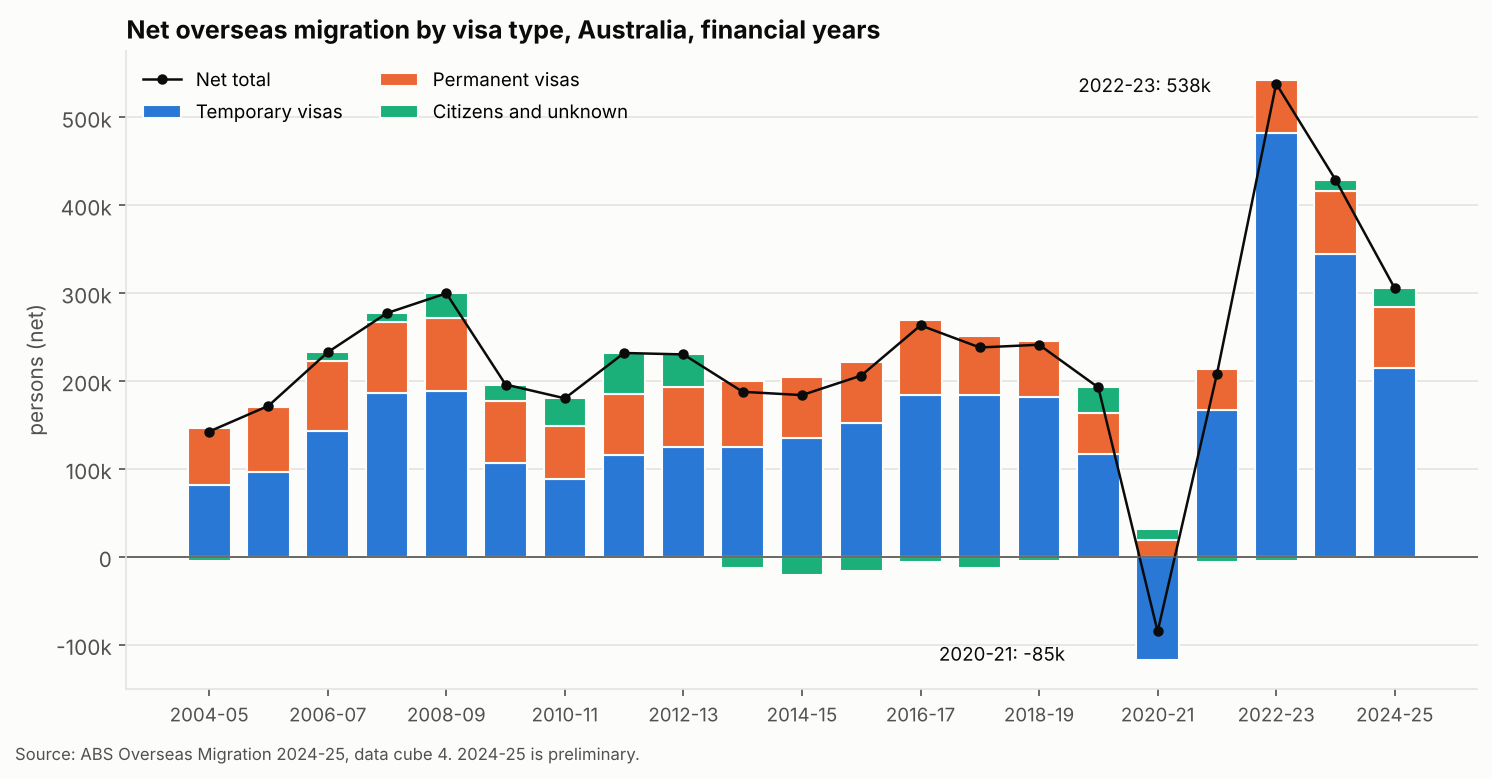

kind,Temporary visas,Permanent visas,Citizens and unknown,total
fy_end,,,,
2016,152.5,69.6,-15.8,206.2
2017,183.6,85.7,-6.0,263.4
2018,183.8,67.3,-12.9,238.2
2019,182.1,63.8,-4.6,241.3
2020,116.8,46.5,29.4,192.7
2021,-117.0,19.0,13.0,-84.9
2022,166.8,47.4,-6.3,207.9
2023,482.3,60.2,-4.2,538.3
2024,344.4,72.4,12.4,429.2


In [3]:
type_map = {"Temporary": "Temporary visas", "Permanent": "Permanent visas",
            "NZ citizen": "Citizens and unknown", "Australian citizen": "Citizens and unknown",
            "Unknown": "Citizens and unknown"}
nat = (aus.assign(kind=aus["visa_type"].map(type_map))
          .pivot_table(index="fy_end", columns="kind", values="net", aggfunc="sum"))
nat = nat[["Temporary visas", "Permanent visas", "Citizens and unknown"]]
nat_total = nat.sum(axis=1)

fig, ax = plt.subplots(figsize=(10, 5.2))
colours = {"Temporary visas": cs.BLUE, "Permanent visas": cs.ORANGE, "Citizens and unknown": cs.AQUA}
pos_base = np.zeros(len(nat))
neg_base = np.zeros(len(nat))
for col in nat.columns:
    vals = nat[col].values
    base = np.where(vals >= 0, pos_base, neg_base)
    ax.bar(nat.index, vals, bottom=base, width=0.72, color=colours[col], label=col,
           edgecolor=cs.SURFACE, linewidth=1)
    pos_base += np.where(vals >= 0, vals, 0)
    neg_base += np.where(vals < 0, vals, 0)
ax.plot(nat.index, nat_total.values, color=cs.INK, marker="o", markersize=4, linewidth=1.2, label="Net total")
ax.axhline(0, color=cs.INK_SOFT, linewidth=0.8)
ax.annotate(f"2022-23: {nat_total[2023]/1000:,.0f}k", (2023, nat_total[2023]), xytext=(-95, -4),
            textcoords="offset points", fontsize=9, color=cs.INK)
ax.annotate(f"2020-21: {nat_total[2021]/1000:,.0f}k", (2021, nat_total[2021]), xytext=(-105, -14),
            textcoords="offset points", fontsize=9, color=cs.INK)
cs.thousands(ax)
ax.set_xticks(nat.index[::2])
ax.set_xticklabels([f"{y-1}-{str(y)[2:]}" for y in nat.index[::2]], fontsize=9)
ax.set_title("Net overseas migration by visa type, Australia, financial years")
ax.set_ylabel("persons (net)")
ax.legend(loc="upper left", ncol=2, fontsize=9)
cs.source_note(fig, "Source: ABS Overseas Migration 2024-25, data cube 4. 2024-25 is preliminary.")
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(IMAGES / "01_nom_by_visa_type.png")
plt.show()

(nat.assign(total=nat_total) / 1000).round(1).loc[2016:]

The 2022-23 peak of 538k was more than double the 241k of 2018-19, and temporary visa
holders made up 482k of it. By 2024-25 (preliminary) the total was back to 306k. That's
still above any pre-COVID year, but the drop from the peak is steep. Permanent visa NOM
barely moves through all of this, because the permanent program is capped.

## 2. Arrivals or departures?

The bar chart only shows the net figure. Net is arrivals minus departures, and those two
moved very differently. Here are temporary visa holders only, against their 2015-16 to
2018-19 average (dashed).

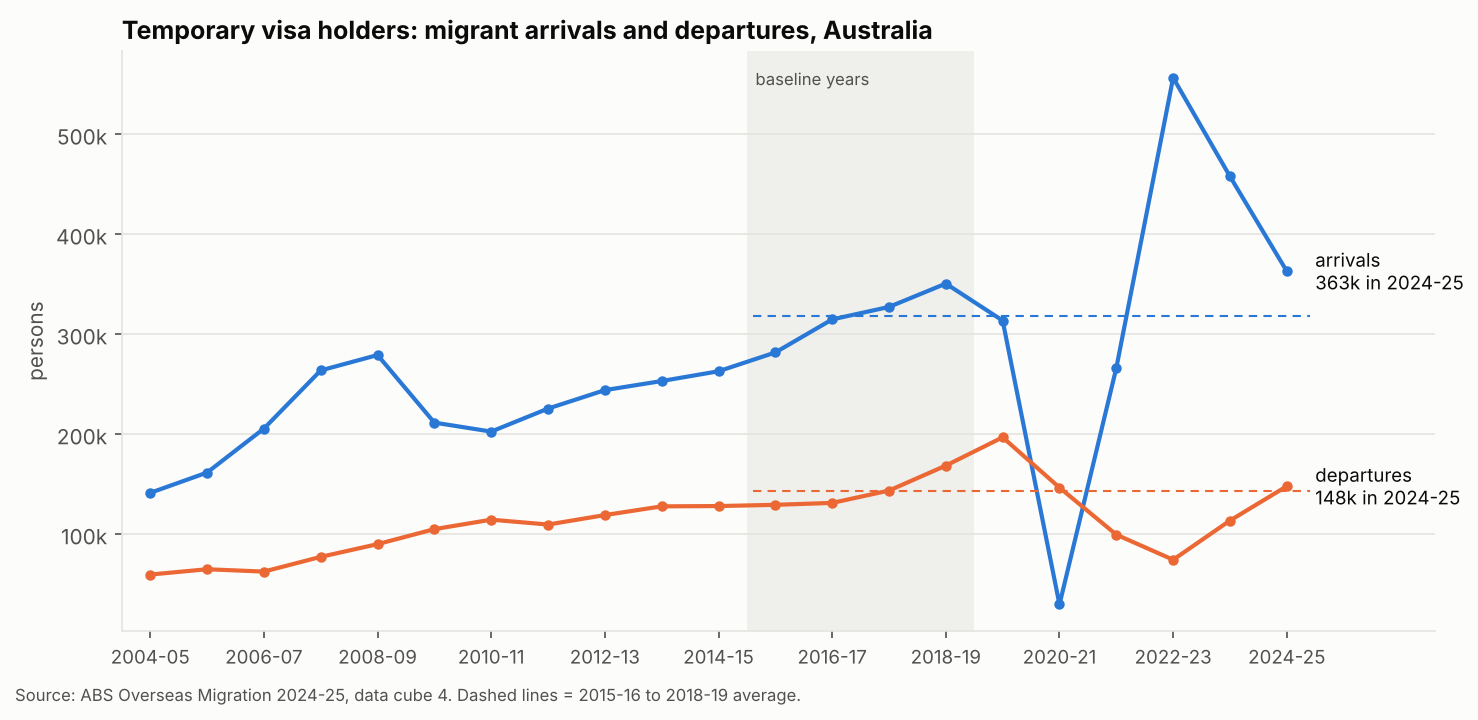

,arrivals,departures
fy_end,,
2019,350.7,168.5
2020,313.6,196.8
2021,29.6,146.5
2022,266.2,99.5
2023,556.6,74.3
2024,457.9,113.6
2025,363.1,147.9


In [4]:
BASE_YEARS = [2016, 2017, 2018, 2019]          # 2015-16 to 2018-19
POST_YEARS = [2021, 2022, 2023, 2024, 2025]    # 2020-21 to 2024-25

temp = aus[aus["visa_type"] == "Temporary"].groupby("fy_end")[["arrivals", "departures"]].sum()
temp_base = temp.loc[BASE_YEARS].mean()

fig, ax = plt.subplots(figsize=(10, 4.8))
for col, colour in [("arrivals", cs.BLUE), ("departures", cs.ORANGE)]:
    ax.plot(temp.index, temp[col], color=colour, marker="o", markersize=4)
    ax.hlines(temp_base[col], BASE_YEARS[0] - 0.4, 2025.4, colors=colour, linestyles=(0, (4, 3)), linewidth=1)
    ax.text(2025.5, temp[col].iloc[-1], f"{col}\n{temp[col].iloc[-1]/1000:,.0f}k in 2024-25",
            color=cs.INK, fontsize=9, va="center")
ax.axvspan(BASE_YEARS[0] - 0.5, BASE_YEARS[-1] + 0.5, color=cs.GRID, alpha=0.5, linewidth=0)
ax.text(BASE_YEARS[0] - 0.35, ax.get_ylim()[1] * 0.97, "baseline years", fontsize=8, color=cs.INK_SOFT, va="top")
cs.thousands(ax)
ax.set_xlim(2004.5, 2027.6)
ax.set_xticks(temp.index[::2])
ax.set_xticklabels([f"{y-1}-{str(y)[2:]}" for y in temp.index[::2]], fontsize=9)
ax.set_title("Temporary visa holders: migrant arrivals and departures, Australia")
ax.set_ylabel("persons")
cs.source_note(fig, "Source: ABS Overseas Migration 2024-25, data cube 4. Dashed lines = 2015-16 to 2018-19 average.")
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(IMAGES / "02_temporary_arrivals_departures.png")
plt.show()

(temp.loc[2019:] / 1000).round(1)

This is the chart that changed how I read the first one. Temporary arrivals did spike to
557k in 2022-23, but the bigger break is in departures. In 2022-23 only 74k temporary visa
holders left, roughly half the pre-COVID average of 143k. Students and working holiday makers
who came in 2022 mostly stayed put. By 2024-25 departures were back to 148k, about normal.

To put a number on it I compare the five years from 2020-21 to 2024-25 with what five
"normal" years would have looked like, using the 2015-16 to 2018-19 average as normal.
Anything above that is the excess, and I split the excess into an arrivals part and a
departures part. Fewer departures than normal counts as a positive contribution.

In [5]:
def excess_vs_baseline(df, by, base_years=BASE_YEARS, post_years=POST_YEARS):
    yearly = df.groupby(by + ["fy_end"])[["arrivals", "departures", "net"]].sum().reset_index()
    base = yearly[yearly["fy_end"].isin(base_years)].groupby(by)[["arrivals", "departures", "net"]].mean()
    post = yearly[yearly["fy_end"].isin(post_years)].groupby(by)[["arrivals", "departures", "net"]].sum()
    out = pd.DataFrame({
        "actual_net": post["net"],
        "baseline_net": base["net"] * len(post_years),
        "from_arrivals": post["arrivals"] - base["arrivals"] * len(post_years),
        "from_fewer_departures": -(post["departures"] - base["departures"] * len(post_years)),
    })
    out["excess_net"] = out["from_arrivals"] + out["from_fewer_departures"]
    return out

by_group = excess_vs_baseline(aus, ["visa_group"])
(by_group.sort_values("excess_net", ascending=False) / 1000).round(1)

,actual_net,baseline_net,from_arrivals,from_fewer_departures,excess_net
visa_group,,,,,
Student,595.5,487.2,27.1,81.2,108.4
Working holiday,201.6,124.4,2.9,74.3,77.2
NZ citizen (444),108.8,35.5,29.7,43.5,73.3
Skilled (temporary),134.2,71.0,23.9,39.3,63.2
Other temporary,-58.5,-80.6,100.7,-78.7,22.1
Unknown visa,-2.2,-16.6,-29.6,44.0,14.4
Other permanent,0.5,-3.0,11.7,-8.2,3.5
Australian citizen,-70.7,-68.0,-81.4,78.7,-2.8
Humanitarian & special eligibility,53.1,77.7,-24.6,0.1,-24.5


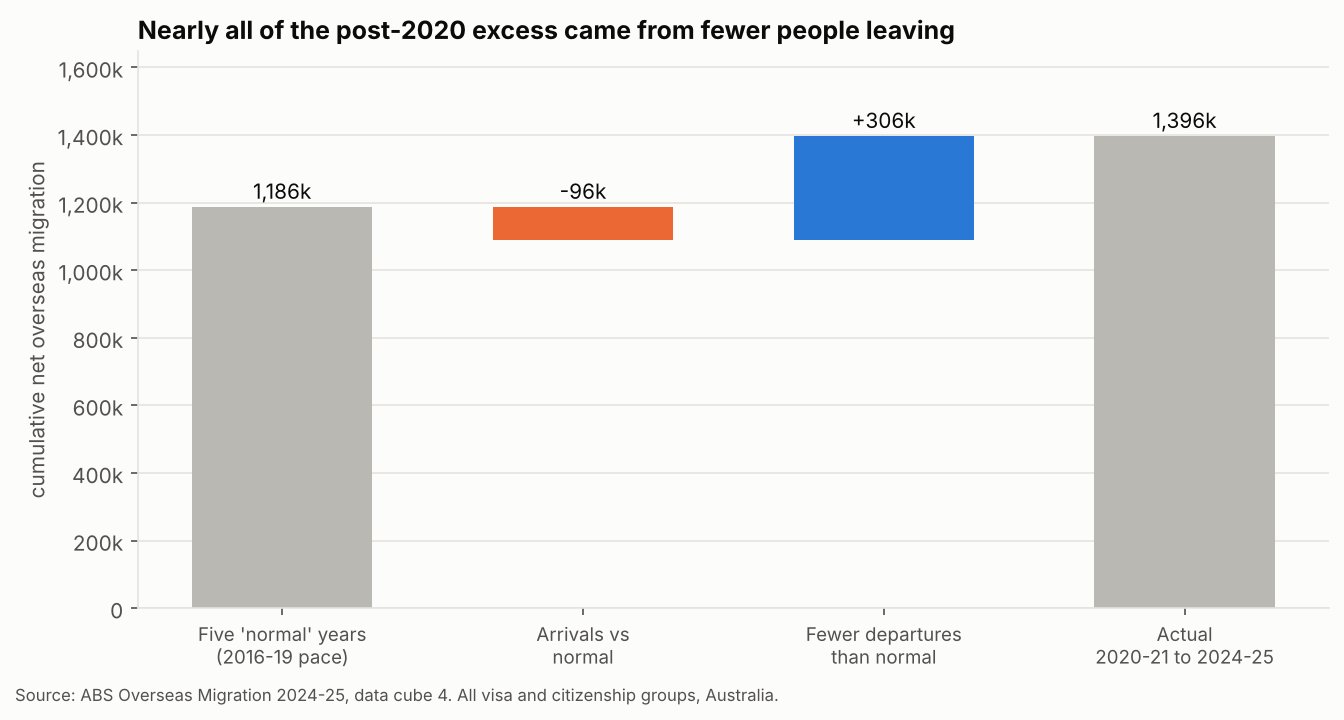

actual_net               1396.0
baseline_net             1186.4
from_arrivals             -96.1
from_fewer_departures     305.8
excess_net                209.6
Name: Australia, dtype: float64

In [6]:
nat_x = excess_vs_baseline(aus.assign(all="Australia"), ["all"]).iloc[0]

steps = [("Five 'normal' years\n(2016-19 pace)", nat_x["baseline_net"], "total"),
         ("Arrivals vs\nnormal", nat_x["from_arrivals"], "step"),
         ("Fewer departures\nthan normal", nat_x["from_fewer_departures"], "step"),
         ("Actual\n2020-21 to 2024-25", nat_x["actual_net"], "total")]

fig, ax = plt.subplots(figsize=(9, 4.8))
running = 0
for i, (label, value, kind) in enumerate(steps):
    if kind == "total":
        ax.bar(i, value, color=cs.CONTEXT_GREY, width=0.6)
        running = value
        y_text = value
    else:
        bottom = running if value >= 0 else running + value
        ax.bar(i, abs(value), bottom=bottom, color=cs.BLUE if value >= 0 else cs.ORANGE, width=0.6)
        running += value
        y_text = max(running, running - value)
    sign = "+" if kind == "step" and value >= 0 else ""
    ax.text(i, y_text + 25_000, f"{sign}{value/1000:,.0f}k", ha="center", fontsize=10, color=cs.INK)
ax.set_xticks(range(len(steps)))
ax.set_xticklabels([s[0] for s in steps], fontsize=9)
cs.thousands(ax)
ax.set_ylim(0, max(nat_x["actual_net"], nat_x["baseline_net"]) * 1.18)
ax.set_title("Nearly all of the post-2020 excess came from fewer people leaving")
ax.set_ylabel("cumulative net overseas migration")
cs.source_note(fig, "Source: ABS Overseas Migration 2024-25, data cube 4. All visa and citizenship groups, Australia.")
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(IMAGES / "03_excess_waterfall.png")
plt.show()

(nat_x / 1000).round(1)

The obvious worry is that this depends on which years I call "normal". So I re-run it with
five different baselines, plus a straight-line trend fitted to 2009-10 to 2018-19.

In [7]:
national = aus.groupby("fy_end")[["arrivals", "departures", "net"]].sum()
rows = []
for label, yrs in [("2011-12 to 2018-19", range(2012, 2020)), ("2013-14 to 2017-18", range(2014, 2019)),
                   ("2014-15 to 2018-19", range(2015, 2020)), ("2015-16 to 2018-19 (main)", range(2016, 2020)),
                   ("2016-17 to 2018-19", range(2017, 2020))]:
    r = excess_vs_baseline(aus.assign(all="Aus"), ["all"], base_years=list(yrs)).iloc[0]
    rows.append({"baseline": label, "excess_net": r["excess_net"],
                 "from_arrivals": r["from_arrivals"], "from_fewer_departures": r["from_fewer_departures"]})

# Trend version: extend the 2010-2019 line forward instead of using a flat average.
trend_cols = {}
for col in ["arrivals", "departures"]:
    coef = np.polyfit(range(2010, 2020), national.loc[2010:2019, col], 1)
    trend_cols[col] = national.loc[POST_YEARS, col].sum() - np.polyval(coef, POST_YEARS).sum()
rows.append({"baseline": "linear trend 2009-10 to 2018-19", "excess_net": trend_cols["arrivals"] - trend_cols["departures"],
             "from_arrivals": trend_cols["arrivals"], "from_fewer_departures": -trend_cols["departures"]})
sensitivity = pd.DataFrame(rows).set_index("baseline")
(sensitivity / 1000).round(0)

,excess_net,from_arrivals,from_fewer_departures
baseline,,,
2011-12 to 2018-19,282.0,46.0,235.0
2013-14 to 2017-18,316.0,51.0,265.0
2014-15 to 2018-19,263.0,-35.0,297.0
2015-16 to 2018-19 (main),210.0,-96.0,306.0
2016-17 to 2018-19,158.0,-159.0,317.0
linear trend 2009-10 to 2018-19,86.0,-423.0,509.0


With the flat baselines, the total excess lands somewhere between 158k and 316k people
over the five years. The departures part is stable: 235k to 317k every time. The
arrivals part isn't. It swings from -159k to +51k, so I can't say whether arrivals were
above or below normal. What I can say is that they weren't the main source of the
excess.

The trend version gives a much smaller excess (86k). It assumes departures would have kept
climbing at their 2010s rate. I don't put much weight on it, but it's a fair reminder that
"normal" is a choice.

## 3. Which states are still running hot?

The annual visa file stops at June 2025. The quarterly population release goes to March 2026,
so for the state view I switch to it. To compare states of very different sizes I use the
rolling four-quarter NOM per 1,000 residents (population four quarters earlier as the base).

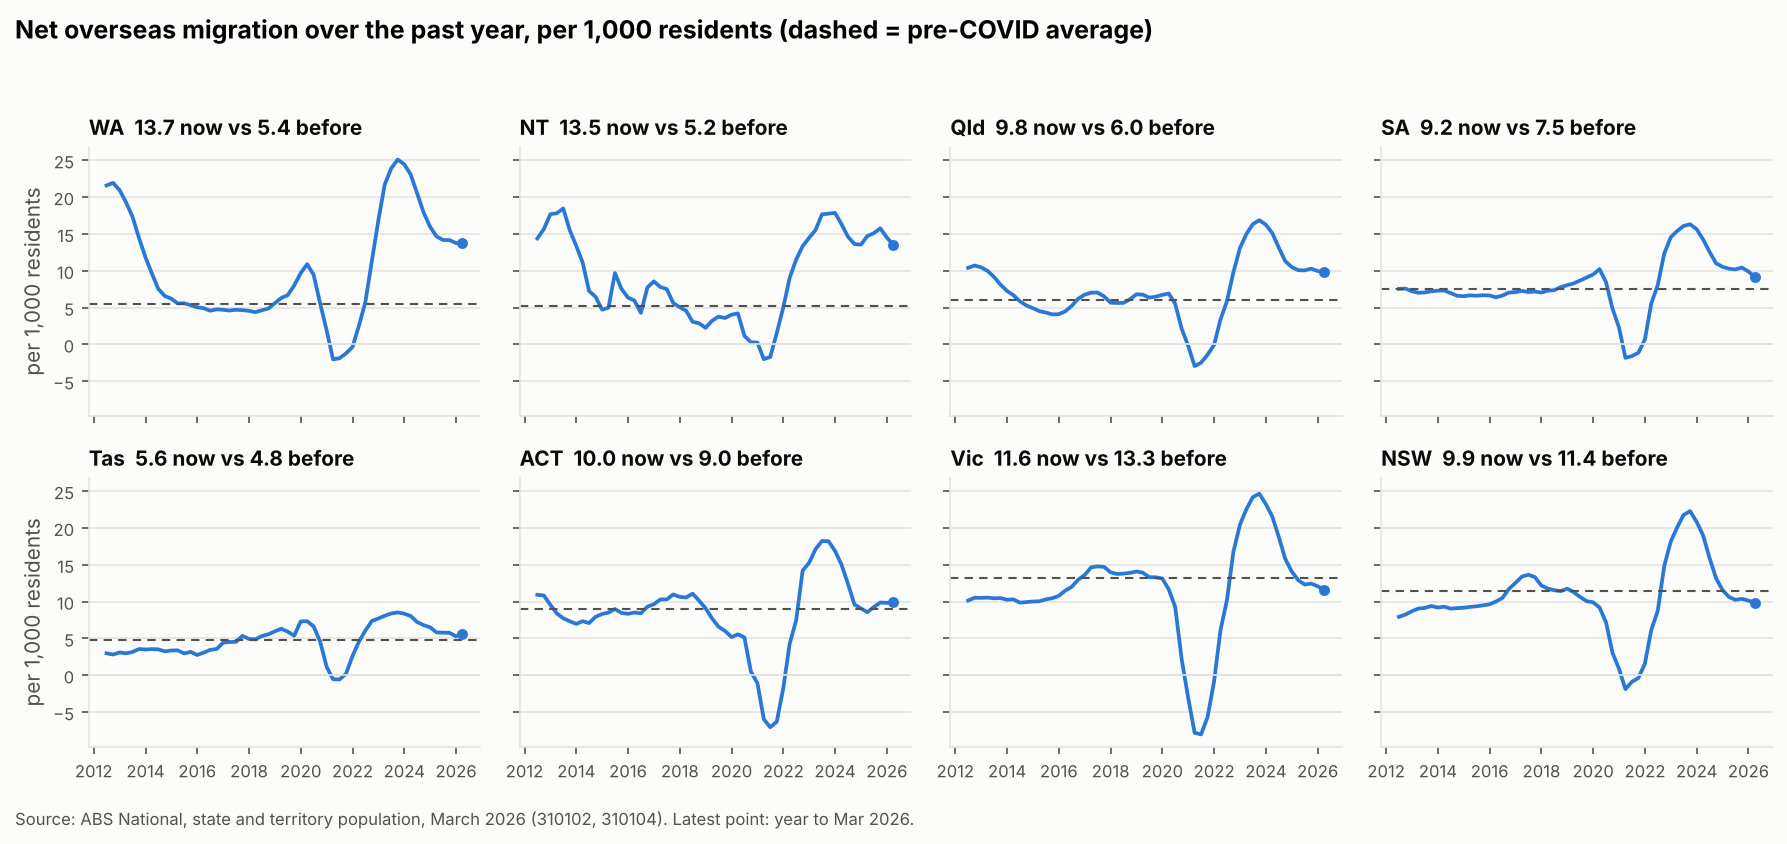

,pre_covid_avg,peak,year_to_mar_2026,now_vs_pre_covid
state_abbr,,,,
NT,5.21,17.85,13.53,2.60
WA,5.44,25.09,13.70,2.52
Qld,5.98,16.86,9.77,1.64
SA,7.50,16.31,9.17,1.22
Tas,4.80,8.52,5.62,1.17
ACT,8.96,18.23,9.96,1.11
Aus,9.63,21.24,10.61,1.10
Vic,13.25,24.64,11.60,0.88
NSW,11.38,22.28,9.86,0.87


In [8]:
pop = pop.sort_values(["state", "quarter_end"]).copy()
pop["nom_4q"] = pop.groupby("state")["nom"].transform(lambda s: s.rolling(4).sum())
pop["erp_year_ago"] = pop.groupby("state")["erp"].shift(4)
pop["nom_per_1000"] = pop["nom_4q"] / pop["erp_year_ago"] * 1000

rate = pop.pivot_table(index="quarter_end", columns="state_abbr", values="nom_per_1000").loc["2012-06-30":]
base_rate = rate.loc["2015-09-30":"2019-12-31"].mean()   # years ending Sep 2015 to Dec 2019
latest = rate.index.max()

order = ["WA", "NT", "Qld", "SA", "Tas", "ACT", "Vic", "NSW"]
fig, axes = plt.subplots(2, 4, figsize=(12, 5.6), sharex=True, sharey=True)
for ax, st in zip(axes.flat, order):
    s = rate[st]
    ax.plot(s.index, s.values, color=cs.BLUE, linewidth=1.8)
    ax.axhline(base_rate[st], color=cs.INK_SOFT, linestyle=(0, (4, 3)), linewidth=1)
    ax.axhline(0, color=cs.GRID, linewidth=0.8)
    ax.scatter([latest], [s.iloc[-1]], color=cs.BLUE, s=18, zorder=3)
    ax.set_title(f"{st}  {s.iloc[-1]:.1f} now vs {base_rate[st]:.1f} before", fontsize=10)
    ax.tick_params(labelsize=8)
for ax in axes[:, 0]:
    ax.set_ylabel("per 1,000 residents")
fig.suptitle("Net overseas migration over the past year, per 1,000 residents (dashed = pre-COVID average)",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
cs.source_note(fig, f"Source: ABS National, state and territory population, March 2026 (310102, 310104). Latest point: year to {latest:%b %Y}.")
fig.tight_layout(rect=(0, 0.04, 1, 0.95))
fig.savefig(IMAGES / "04_state_nom_rates.png")
plt.show()

state_now = pd.DataFrame({"pre_covid_avg": base_rate, "peak": rate.loc["2021":].max(),
                          "year_to_mar_2026": rate.iloc[-1]})
state_now["now_vs_pre_covid"] = state_now["year_to_mar_2026"] / state_now["pre_covid_avg"]
state_now.round(2).sort_values("now_vs_pre_covid", ascending=False)

Nationally, the year to March 2026 ran at 10.6 per 1,000 residents against 9.6 before
COVID, so about 10% above normal. The states split two ways. NSW (9.9 vs 11.4) and
Victoria (11.6 vs 13.3) are now *below* their pre-COVID rates. WA (13.7 vs 5.4), the NT
(13.5 vs 5.2) and Queensland (9.8 vs 6.0) are well above theirs.

One caution on WA. Its pre-COVID window happens to be the trough after the mining boom,
and back in 2012 WA was running above 20 per 1,000. So "2.5 times normal" partly reflects
a low baseline.

Same excess split as before, now by state and scaled by each state's June 2019 population.

In [9]:
by_state = excess_vs_baseline(visa[visa["state"] != "Australia"], ["state_abbr"])
erp_2019 = pop[pop["quarter_end"] == "2019-06-30"].set_index("state_abbr")["erp"]
by_state["excess_per_1000"] = by_state["excess_net"] / erp_2019 * 1000
cols = ["actual_net", "baseline_net", "from_arrivals", "from_fewer_departures", "excess_net"]
out = (by_state[cols] / 1000).round(1)
out["excess_per_1000"] = by_state["excess_per_1000"].round(1)
out.sort_values("excess_per_1000", ascending=False)

,actual_net,baseline_net,from_arrivals,from_fewer_departures,excess_net,excess_per_1000
state_abbr,,,,,,
WA,177.1,66.4,48.7,62.0,110.7,41.6
NT,14.3,5.7,-5.9,14.5,8.6,34.7
Qld,231.8,148.1,-0.3,84.0,83.7,16.4
SA,83.1,64.2,6.9,12.1,18.9,10.7
Tas,14.8,12.6,1.0,1.2,2.2,3.9
ACT,19.5,18.6,-3.4,4.3,0.9,2.0
NSW,466.1,450.9,-73.0,88.2,15.2,1.9
Vic,389.2,419.9,-70.3,39.6,-30.6,-4.7


WA has the biggest excess per head, about 42 extra people per 1,000 residents. It's
also the only state where arrivals clearly beat the baseline (+49k). Queensland's +84k
came almost entirely from fewer departures. Victoria surprised me. Over the five years
it finished about 31k *below* its pre-COVID pace. Per head, its 2020-21 outflow was the
deepest of any state, and the 2023 surge never fully made it up. NSW roughly broke even.

One more check before I trust the latest year. The 2024-25 figures are preliminary. The visa
file (released December 2025) and the quarterly file (September 2026) are different vintages,
so comparing their 2024-25 totals shows how much the estimate has moved already.

In [10]:
fy25_visa = visa[visa["fy_end"] == 2025].groupby("state_abbr")["net"].sum()
fy25_qtr = pop[(pop["quarter_end"] > "2024-06-30") & (pop["quarter_end"] <= "2025-06-30")].groupby("state_abbr")["nom"].sum()
fy24_visa = visa[visa["fy_end"] == 2024].groupby("state_abbr")["net"].sum()
fy24_qtr = pop[(pop["quarter_end"] > "2023-06-30") & (pop["quarter_end"] <= "2024-06-30")].groupby("state_abbr")["nom"].sum()
revisions = pd.DataFrame({
    "2023-24 gap": fy24_qtr - fy24_visa,
    "2024-25 Dec 2025 release": fy25_visa,
    "2024-25 Sep 2026 release": fy25_qtr,
})
revisions["2024-25 revision"] = revisions["2024-25 Sep 2026 release"] - revisions["2024-25 Dec 2025 release"]
revisions["revision %"] = (revisions["2024-25 revision"] / revisions["2024-25 Dec 2025 release"] * 100).round(1)
revisions

,2023-24 gap,2024-25 Dec 2025 release,2024-25 Sep 2026 release,2024-25 revision,revision %
state_abbr,,,,,
ACT,-6.0,4980,4425.0,-555.0,-11.1
Aus,2.0,305570,301572.0,-3998.0,-1.3
NSW,-5.0,91570,86916.0,-4654.0,-5.1
NT,7.0,3600,3938.0,338.0,9.4
Qld,3.0,55750,55959.0,209.0,0.4
SA,-3.0,18730,19154.0,424.0,2.3
Tas,4.0,2730,3324.0,594.0,21.8
Vic,1.0,87770,85603.0,-2167.0,-2.5
WA,2.0,40400,42213.0,1813.0,4.5


2023-24 agrees across both releases to within rounding. For 2024-25 the national total was
revised down 1.3% (306k to 302k), but the small jurisdictions moved a lot: Tasmania +22%,
ACT -11%, NT +9%. So I treat the latest year for the small states as plus or minus 10-20%,
and the big-state numbers as reasonably firm.

## 4. If fewer people left, where are they? Home Affairs visa holder counts

The ABS figures are flows. Home Affairs publishes a stock: how many temporary visa holders
are in the country on a snapshot date. If the departures story is right, the stock should
still be high even though the inflow has come back down.

My first go at this used every quarterly snapshot and it looked like noise. The snapshots are
strongly seasonal: students leave over the summer break and visitors pile in at Christmas.

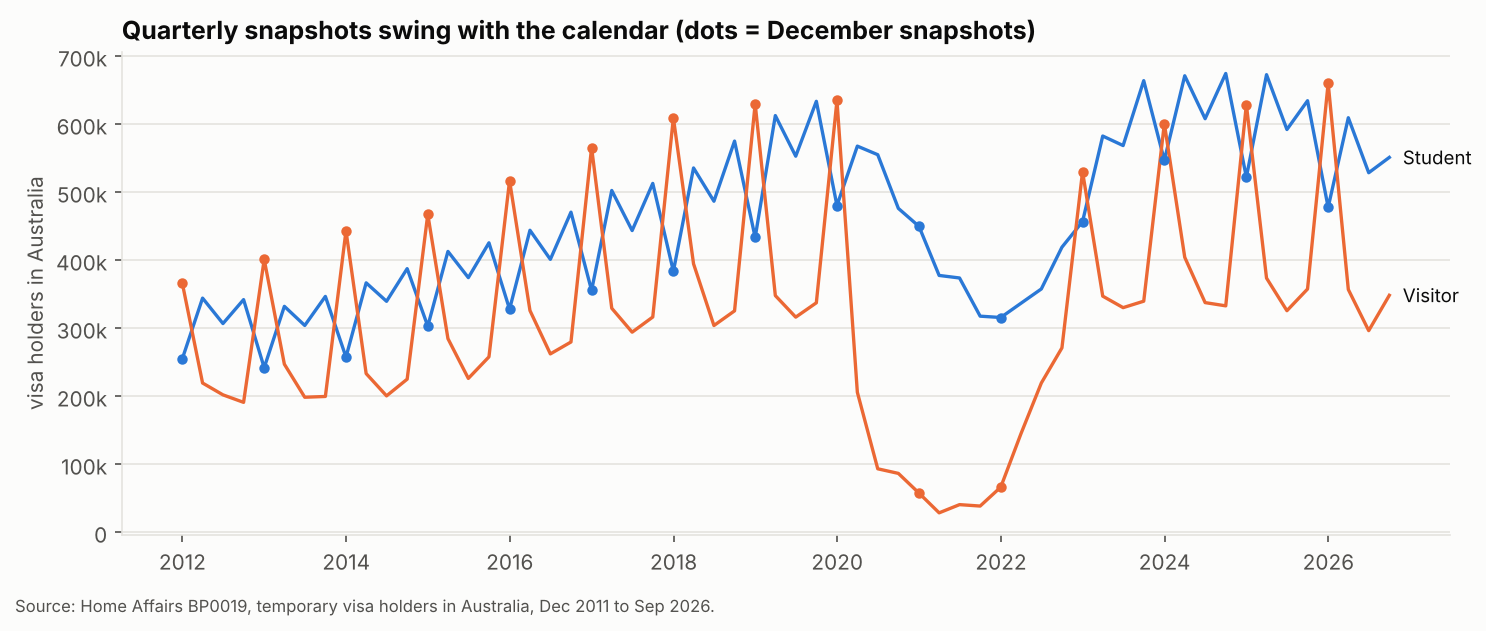

visa_category
Student   -156780.0
Visitor    302730.0
dtype: float64

In [11]:
stock = holders.pivot_table(index="snapshot_date", columns="visa_category", values="visa_holders", aggfunc="sum")

fig, ax = plt.subplots(figsize=(10, 4.2))
for cat, colour in [("Student", cs.BLUE), ("Visitor", cs.ORANGE)]:
    s = stock[cat]
    ax.plot(s.index, s.values, color=colour, linewidth=1.6)
    dec = s[s.index.month == 12]
    ax.scatter(dec.index, dec.values, color=colour, s=16, zorder=3)
    ax.text(s.index[-1] + pd.Timedelta(days=60), s.iloc[-1], cat, color=cs.INK, fontsize=9, va="center")
cs.thousands(ax)
ax.set_title("Quarterly snapshots swing with the calendar (dots = December snapshots)")
ax.set_ylabel("visa holders in Australia")
cs.source_note(fig, "Source: Home Affairs BP0019, temporary visa holders in Australia, Dec 2011 to Sep 2026.")
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(IMAGES / "06_snapshot_seasonality.png")
plt.show()

dec_vs_sep = (stock.loc["2025-12-31"] - stock.loc["2025-09-30"])[["Student", "Visitor"]]
dec_vs_sep

So I only compare June snapshots with June snapshots. June also lines up with the end of
the ABS financial year.

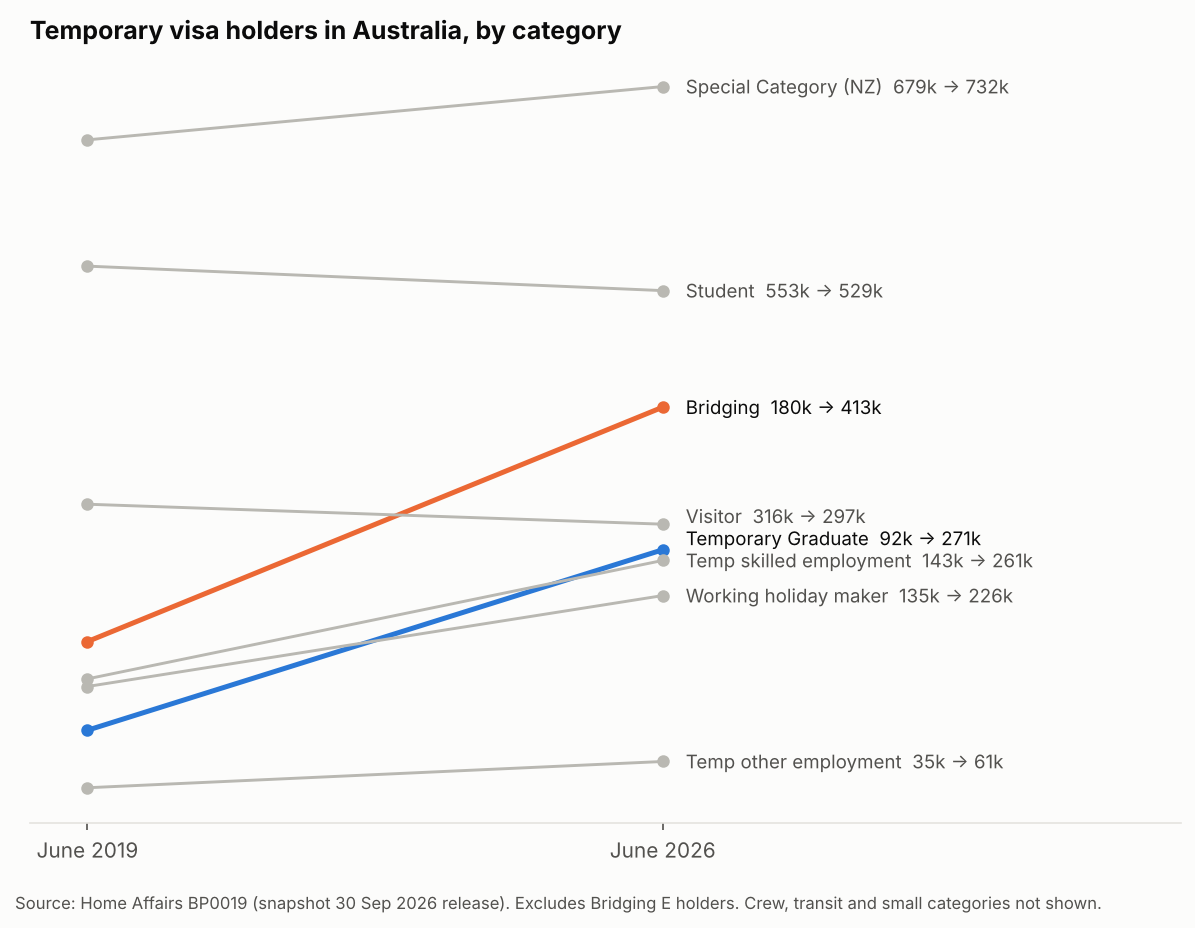

,June 2019,June 2025,June 2026,change 2019 to 2026
visa_category,,,,
Total,2165.0,2766.0,2807.0,642.0
Bridging,180.0,370.0,413.0,233.0
Temporary Graduate,92.0,229.0,271.0,179.0
Temporary Resident (Skilled Employment),143.0,220.0,261.0,118.0
Working Holiday Maker,135.0,211.0,226.0,90.0
Special Category,679.0,736.0,732.0,53.0
Temporary Resident (Other Employment),35.0,62.0,61.0,26.0
Crew and Transit,12.0,14.0,13.0,1.0
Other Temporary,5.0,5.0,5.0,-0.0


In [12]:
june = stock[stock.index.month == 6]
cats = ["Bridging", "Temporary Graduate", "Temporary Resident (Skilled Employment)", "Working Holiday Maker",
        "Student", "Visitor", "Special Category", "Temporary Resident (Other Employment)"]
short = {"Temporary Resident (Skilled Employment)": "Temp skilled employment",
         "Temporary Resident (Other Employment)": "Temp other employment",
         "Working Holiday Maker": "Working holiday maker",
         "Special Category": "Special Category (NZ)"}
start, end = pd.Timestamp("2019-06-30"), pd.Timestamp("2026-06-30")
highlight = {"Bridging": cs.ORANGE, "Temporary Graduate": cs.BLUE}

# Push end labels apart so close values (graduate, skilled, visitor) don't overprint.
label_y = june.loc[end, cats].sort_values()
min_gap = 22_000
placed = []
for cat, y in label_y.items():
    if placed and y - placed[-1][1] < min_gap:
        y = placed[-1][1] + min_gap
    placed.append((cat, y))
label_pos = dict(placed)

fig, ax = plt.subplots(figsize=(8, 6.2))
for cat in cats:
    a, b = june.loc[start, cat], june.loc[end, cat]
    colour = highlight.get(cat, cs.CONTEXT_GREY)
    ax.plot([0, 1], [a, b], color=colour, linewidth=2.4 if cat in highlight else 1.4, marker="o", markersize=5)
    name = short.get(cat, cat)
    ax.text(1.04, label_pos[cat], f"{name}  {a/1000:,.0f}k → {b/1000:,.0f}k", va="center", fontsize=9,
            color=cs.INK if cat in highlight else cs.INK_SOFT)
ax.set_xlim(-0.1, 1.9)
ax.set_xticks([0, 1])
ax.set_xticklabels(["June 2019", "June 2026"])
ax.grid(False)
ax.spines["left"].set_visible(False)
ax.set_yticks([])
ax.set_title("Temporary visa holders in Australia, by category")
cs.source_note(fig, "Source: Home Affairs BP0019 (snapshot 30 Sep 2026 release). Excludes Bridging E holders. Crew, transit and small categories not shown.")
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(IMAGES / "05_visa_holder_stock_2019_2026.png")
plt.show()

change = pd.DataFrame({"June 2019": june.loc[start], "June 2025": june.loc["2025-06-30"], "June 2026": june.loc[end]})
change["change 2019 to 2026"] = change["June 2026"] - change["June 2019"]
change.loc["Total"] = change.sum()
(change / 1000).round(0).sort_values("change 2019 to 2026", ascending=False)

This lines up with the departures story. Temporary visa holders in Australia went from
2.17m in June 2019 to 2.81m in June 2026 (+642k). Student numbers are actually slightly
*below* 2019 (529k vs 553k). The growth is in Bridging (+233k), Temporary Graduate (+179k),
temporary skilled (+118k) and working holiday makers (+90k). The September 2026 snapshot
(2.93m) is the highest September in the series.

My reading is that the 2022-23 cohort hasn't left. Much of it has moved from student visas
onto graduate and bridging visas. A bridging visa means someone is between visas, often
waiting on a decision. This file doesn't say what they're waiting on, so I can't tell how
many will end up permanent and how many will leave.

The thing I tried that didn't work: matching the two sources visa group by visa group.
If 600k net students came in, shouldn't the student stock be up by about that much?

In [13]:
pairs = {"Student": "Student", "Working holiday": "Working Holiday Maker",
         "Skilled (temporary)": "Temporary Resident (Skilled Employment)", "Visitor": "Visitor"}
cum_nom = aus[aus["fy_end"].between(2020, 2025)].groupby("visa_group")["net"].sum()
stock_change = june.loc["2025-06-30"] - june.loc["2019-06-30"]
recon = pd.DataFrame({
    "ABS net migration, 2019-20 to 2024-25": [cum_nom[k] for k in pairs],
    "Home Affairs stock change, Jun 2019 to Jun 2025": [stock_change[v] for v in pairs.values()],
}, index=list(pairs))
recon.loc["All temporary (ABS) vs all non-visitor temp categories (HA)"] = [
    cum_nom[["Student", "Skilled (temporary)", "Working holiday", "Visitor", "Other temporary"]].sum(),
    stock_change.drop(["Visitor", "Special Category", "Crew and Transit"]).sum()]
(recon / 1000).round(0)

,"ABS net migration, 2019-20 to 2024-25","Home Affairs stock change, Jun 2019 to Jun 2025"
Student,605.0,39.0
Working holiday,220.0,76.0
Skilled (temporary),143.0,77.0
Visitor,320.0,10.0
All temporary (ABS) vs all non-visitor temp categories (HA),1208.0,532.0


It doesn't reconcile, and not because of a bug. The ABS records the visa a person holds when
they cross the border. Someone who arrives on a student visa and leaves on a graduate visa
adds to "Student" and subtracts from "Other temporary". People who get a permanent visa
onshore drop out of the Home Affairs temporary count without ever leaving. So the 605k net
student figure and the 39k change in the student stock are measuring different things. Even
at the all-temporary level the gap is about 680k. Part of that is onshore permanent grants,
and I can't size the rest from these two files. I dropped the group-by-group matching and
only use the stock as a direction check.

Last thing: who holds the graduate visas.

In [14]:
grad = grads_by_country[grads_by_country["visa_category"] == "Temporary Graduate"]
g = grad.pivot_table(index="citizenship_country", columns="snapshot_date", values="visa_holders", aggfunc="sum")
g = g[[pd.Timestamp("2019-06-30"), pd.Timestamp("2026-06-30")]].fillna(0)
g.columns = ["June 2019", "June 2026"]
g["share of June 2026"] = (g["June 2026"] / g["June 2026"].sum() * 100).round(1)
g.sort_values("June 2026", ascending=False).head(6)

,June 2019,June 2026,share of June 2026
citizenship_country,,,
India,28171.0,92588.0,34.1
Nepal,11169.0,35241.0,13.0
"China, Peoples Republic of (excl SARs)",17104.0,30820.0,11.4
Philippines,2671.0,13422.0,4.9
Pakistan,4286.0,12878.0,4.7
Bhutan,746.0,12001.0,4.4


India alone is about a third of Temporary Graduate holders, and Nepal and China make up
another quarter. Bhutan grew from under 1k to 12k. If graduate visa rules change for a
particular cohort, the effect on departures will be concentrated, not spread evenly.

## Where this leaves me

The headline number (538k) reads like an arrivals story. The data says it's mostly a
departures story. People who arrived from 2022 onward stayed longer than earlier cohorts
did, and the stock of temporary visa holders is still at a record. The inflow is now close
to normal nationally, and below normal in NSW and Victoria. The states still running hot,
relative to their own history, are WA, the NT and Queensland.

Limits are in the README. The big ones: this is all correlation and accounting, not cause;
2024-25 is preliminary; and the ABS visa groups and the Home Affairs categories don't map
one to one.